# Course 11: Mathematics for Machine Learning
## Session 7: Statistics and estimation: MLE, MAP and uncertainty

**Goal:** derive maximum likelihood and MAP estimates for a coin and a Gaussian, fit ridge regression as a MAP estimate, and put a bootstrap confidence interval on a classifier's test accuracy.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. By hand first: a coin and a Gaussian
Do these two on paper before you run the cell.

* **The coin.** You flip a coin 3 times and get 3 heads. The log-likelihood is $\log L(p) = k \log p + (n-k)\log(1-p)$ with $k = 3$, $n = 3$. What is the maximum likelihood estimate (MLE) of $p$? With a Beta(2, 2) prior, $p(p) \propto p(1-p)$, the maximum a posteriori (MAP) estimate is $(k+1)/(n+2)$. What is it here?
* **The Gaussian.** Data 2, 4, 6 are modelled as draws from $N(\mu, \sigma^2)$. The MLE is $\hat\mu = \bar x$ and $\hat\sigma^2 = \frac{1}{n}\sum_i (x_i - \bar x)^2$. Compute both.

The cell checks your answers by maximizing numerically, with no formula: a grid search for the coin and `scipy.optimize.minimize` for the Gaussian.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize, stats
from scipy.special import xlogy, xlog1py

t_start = time.time()
np.random.seed(0)

# (a) the coin: 3 heads in 3 flips
k, n = 3, 3
p = np.linspace(0, 1, 100001)                                   # a fine grid of candidate values of p
with np.errstate(divide="ignore"):
    loglik = xlogy(k, p) + xlog1py(n - k, -p)                   # k log p + (n - k) log(1 - p), with 0 log 0 = 0
    logpost = loglik + stats.beta(2, 2).logpdf(p)               # log likelihood + log prior (+ a constant)
print(f"coin, {k} heads in {n} flips: MLE {p[loglik.argmax()]:.3f} (formula k/n = {k / n:.3f}); "
      f"MAP with a Beta(2, 2) prior {p[logpost.argmax()]:.3f} (formula (k+1)/(n+2) = {(k + 1) / (n + 2):.3f})")

# (b) the Gaussian: data 2, 4, 6
x = np.array([2.0, 4.0, 6.0])
nll = lambda t: -stats.norm(t[0], np.exp(t[1])).logpdf(x).sum()   # t = (mu, log sigma), so sigma stays positive
res = optimize.minimize(nll, x0=[0.0, 0.0])
print(f"Gaussian, data {x}: numerical MLE mu = {res.x[0]:.4f}, sigma^2 = {np.exp(2 * res.x[1]):.4f}")
print(f"formulas: mean {x.mean():.4f}; variance dividing by n {x.var(ddof=0):.4f}; dividing by n - 1 {x.var(ddof=1):.4f}")

coin, 3 heads in 3 flips: MLE 1.000 (formula k/n = 1.000); MAP with a Beta(2, 2) prior 0.800 (formula (k+1)/(n+2) = 0.800)
Gaussian, data [2. 4. 6.]: numerical MLE mu = 4.0000, sigma^2 = 2.6667
formulas: mean 4.0000; variance dividing by n 2.6667; dividing by n - 1 4.0000


### 2. Losses are negative log-likelihoods
Two facts that explain most training losses:

* **Squared error is Gaussian noise.** If $y = f_\theta(x) + \varepsilon$ with $\varepsilon \sim N(0, \sigma^2)$, then $-\log p(y \mid x) = \frac{(y - f_\theta(x))^2}{2\sigma^2} + \frac12 \log(2\pi\sigma^2)$. For fixed $\sigma$, minimizing the negative log-likelihood (NLL) over $\theta$ is minimizing the squared error.
* **Cross-entropy is the NLL of a categorical model.** If the model gives probability $q_\theta(y \mid x)$ to class $y$, the NLL of the data is $-\sum_i \log q_\theta(y_i \mid x_i)$, which is exactly the cross-entropy loss.

The cell checks both numerically on small examples.

In [2]:
from sklearn.metrics import log_loss

rng = np.random.default_rng(0)
xs = rng.uniform(-2, 2, 50); ys = 3 * xs + 1 + rng.normal(0, 0.5, 50)
ws = np.linspace(2, 4, 2001)                                    # candidate slopes, intercept fixed at 1
sse = [((ys - (w * xs + 1)) ** 2).sum() for w in ws]
gauss_nll = [-stats.norm(w * xs + 1, 0.5).logpdf(ys).sum() for w in ws]
print(f"slope minimizing squared error {ws[np.argmin(sse)]:.3f}; slope minimizing Gaussian NLL {ws[np.argmin(gauss_nll)]:.3f}")

q = np.array([[0.7, 0.2, 0.1], [0.1, 0.8, 0.1], [0.3, 0.3, 0.4]])   # a model's probabilities for 3 examples
y_true = np.array([0, 1, 2])
print(f"mean NLL by hand {-np.log(q[np.arange(3), y_true]).mean():.4f}; sklearn log_loss (cross-entropy) {log_loss(y_true, q):.4f}")

slope minimizing squared error 3.066; slope minimizing Gaussian NLL 3.066
mean NLL by hand 0.4987; sklearn log_loss (cross-entropy) 0.4987


### 3. MLE against MAP for coin flips, with few and many flips
For $k$ heads in $n$ flips, the MLE $k/n$ is unbiased with variance $p(1-p)/n$. The MAP estimate with a Beta(2, 2) prior, $(k+1)/(n+2)$, acts as if you had seen one extra head and one extra tail. It is biased towards 0.5, with bias $(1-2p)/(n+2)$ and variance $np(1-p)/(n+2)^2$. The mean squared error (MSE) of an estimator is $\text{bias}^2 + \text{variance}$.

We simulate 20,000 experiments for each $n$, for a true $p = 0.7$ (the prior's guess of 0.5 is not far off) and $p = 0.95$ (the prior is badly off), and compare the simulated MSE with the formulas.

true p |    n | MSE of MLE: simulated (formula) | MSE of MAP: simulated (formula)
  0.70 |    3 | 0.06984 (0.07000)            | 0.03138 (0.03160)
  0.70 |   10 | 0.02063 (0.02100)            | 0.01543 (0.01569)
  0.70 |   30 | 0.00713 (0.00700)            | 0.00643 (0.00631)
  0.70 |  100 | 0.00207 (0.00210)            | 0.00201 (0.00203)
  0.70 | 1000 | 0.00021 (0.00021)            | 0.00021 (0.00021)
  0.95 |    3 | 0.01549 (0.01583)            | 0.03774 (0.03810)
  0.95 |   10 | 0.00472 (0.00475)            | 0.00882 (0.00892)
  0.95 |   30 | 0.00159 (0.00158)            | 0.00219 (0.00218)
  0.95 |  100 | 0.00048 (0.00048)            | 0.00054 (0.00053)
  0.95 | 1000 | 0.00005 (0.00005)            | 0.00005 (0.00005)


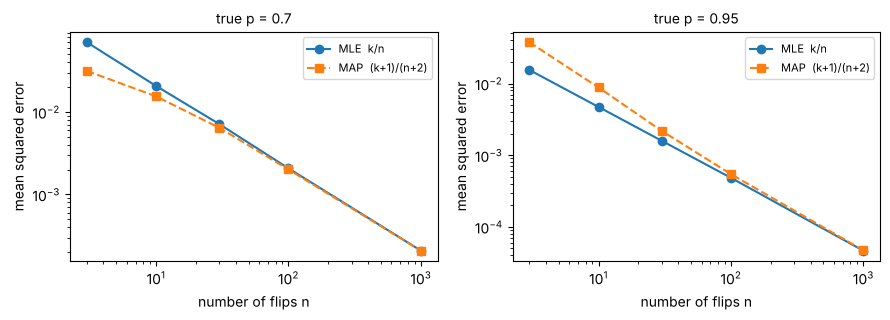

In [3]:
rng = np.random.default_rng(1)
ns, R = [3, 10, 30, 100, 1000], 20000
mse = {}
print("true p |    n | MSE of MLE: simulated (formula) | MSE of MAP: simulated (formula)")
for p_true in [0.7, 0.95]:
    for n_ in ns:
        k_ = rng.binomial(n_, p_true, size=R)                       # R experiments of n_ flips each
        mle, map_ = k_ / n_, (k_ + 1) / (n_ + 2)
        f_mle = p_true * (1 - p_true) / n_
        f_map = ((1 - 2 * p_true) / (n_ + 2)) ** 2 + n_ * p_true * (1 - p_true) / (n_ + 2) ** 2
        mse[p_true, n_] = ((mle - p_true) ** 2).mean(), ((map_ - p_true) ** 2).mean()
        print(f"{p_true:6.2f} | {n_:4d} | {mse[p_true, n_][0]:.5f} ({f_mle:.5f})            | {mse[p_true, n_][1]:.5f} ({f_map:.5f})")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
for a, p_true in zip(ax, [0.7, 0.95]):
    a.loglog(ns, [mse[p_true, m][0] for m in ns], "o-", label="MLE  k/n")
    a.loglog(ns, [mse[p_true, m][1] for m in ns], "s--", label="MAP  (k+1)/(n+2)")
    a.set_xlabel("number of flips n"); a.set_ylabel("mean squared error"); a.set_title(f"true p = {p_true}", fontsize=10)
    a.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 4. Bias and variance of the Gaussian variance estimate
The MLE of the variance divides by $n$. Its average is $\frac{n-1}{n}\sigma^2$, so it is biased low; dividing by $n - 1$ removes the bias. Unbiased is not the same as more accurate: for Gaussian data the MSE of the $1/n$ version is $(2n-1)\sigma^4/n^2$ and that of the $1/(n-1)$ version is $2\sigma^4/(n-1)$. We draw 100,000 data sets of $n = 5$ points with $\sigma^2 = 4$.

In [4]:
rng = np.random.default_rng(2)
nv, s2 = 5, 4.0
samples = rng.normal(0, np.sqrt(s2), size=(100000, nv))
v_mle, v_unb = samples.var(axis=1, ddof=0), samples.var(axis=1, ddof=1)
print(f"average of the 1/n estimate      {v_mle.mean():.3f}   (theory (n-1)/n * 4 = {(nv - 1) / nv * s2:.3f})")
print(f"average of the 1/(n-1) estimate  {v_unb.mean():.3f}   (theory 4)")
print(f"MSE of the 1/n estimate      {((v_mle - s2) ** 2).mean():.2f}   (theory (2n-1)/n^2 * 16 = {(2 * nv - 1) / nv**2 * s2**2:.2f})")
print(f"MSE of the 1/(n-1) estimate  {((v_unb - s2) ** 2).mean():.2f}   (theory 2/(n-1) * 16 = {2 / (nv - 1) * s2**2:.2f})")

average of the 1/n estimate      3.200   (theory (n-1)/n * 4 = 3.200)
average of the 1/(n-1) estimate  3.999   (theory 4)
MSE of the 1/n estimate      5.76   (theory (2n-1)/n^2 * 16 = 5.76)
MSE of the 1/(n-1) estimate  8.00   (theory 2/(n-1) * 16 = 8.00)


### 5. Ridge regression is MAP with a Gaussian prior
Model: $y = Xw + \varepsilon$ with $\varepsilon \sim N(0, \sigma^2 I)$ and prior $w \sim N(0, \tau^2 I)$. The negative log posterior is, up to a constant,

$$\frac{\|y - Xw\|^2}{2\sigma^2} + \frac{\|w\|^2}{2\tau^2}.$$

Multiplying by $2\sigma^2$ gives the ridge loss $\|y - Xw\|^2 + \lambda\|w\|^2$ with $\lambda = \sigma^2/\tau^2$, minimized by $w = (X^\top X + \lambda I)^{-1}X^\top y$. A stronger prior (smaller $\tau$) means a larger $\lambda$.

First we check that three routes give the same $w$: minimizing the negative log posterior numerically, the closed form, and scikit-learn's `Ridge`. Then we draw 500 small regression problems whose true weights really come from the prior ($d = 20$ features, $\sigma = 1$, $\tau = 0.5$, so $\sigma^2/\tau^2 = 4$), and average the test error over a sweep of $\lambda$, for $n = 30$ and $n = 200$ training points.

lambda = sigma^2/tau^2 = 4: max |closed form - numerical MAP| = 2.9e-08; max |closed form - sklearn Ridge| = 6.7e-16


n =  30: best lambda on the grid 3.98 (sigma^2/tau^2 = 4); mean test MSE at lambda = 0.001 3.139, at lambda = 3.98 2.091, at lambda = 1000 5.610 (noise floor sigma^2 = 1)


n = 200: best lambda on the grid 3.98 (sigma^2/tau^2 = 4); mean test MSE at lambda = 0.001 1.111, at lambda = 3.98 1.109, at lambda = 1000 4.557 (noise floor sigma^2 = 1)


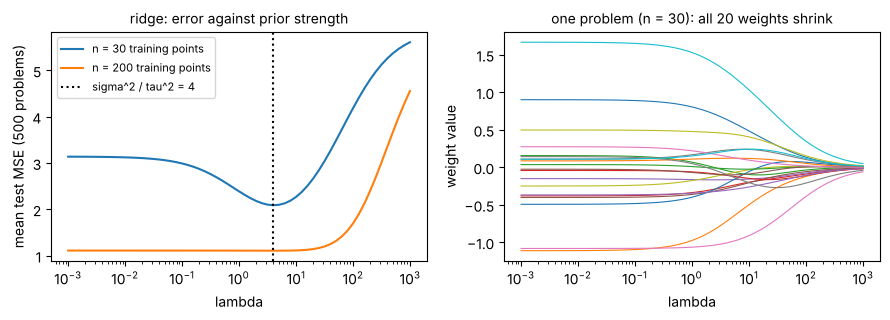

In [5]:
from sklearn.linear_model import Ridge

d, n_test, sigma, tau = 20, 1000, 1.0, 0.5
lam_star = sigma**2 / tau**2

def draw(n_train, rng):
    w = rng.normal(0, tau, d)                                       # true weights drawn from the prior
    X, Xt = rng.normal(size=(n_train, d)), rng.normal(size=(n_test, d))
    return w, X, X @ w + rng.normal(0, sigma, n_train), Xt, Xt @ w + rng.normal(0, sigma, n_test)

rng = np.random.default_rng(3)
w_true, X, y, Xt, yt = draw(30, rng)
w_closed = np.linalg.solve(X.T @ X + lam_star * np.eye(d), X.T @ y)
neg_log_post = lambda v: ((y - X @ v) ** 2).sum() / (2 * sigma**2) + (v ** 2).sum() / (2 * tau**2)
w_num = optimize.minimize(neg_log_post, np.zeros(d), method="BFGS", options={"gtol": 1e-10}).x
w_skl = Ridge(alpha=lam_star, fit_intercept=False).fit(X, y).coef_
print(f"lambda = sigma^2/tau^2 = {lam_star:.0f}: max |closed form - numerical MAP| = {np.abs(w_closed - w_num).max():.1e}; "
      f"max |closed form - sklearn Ridge| = {np.abs(w_closed - w_skl).max():.1e}")

lams = np.logspace(-3, 3, 61)
def sweep(n_train, reps=500, seed=4):
    rng = np.random.default_rng(seed); err = np.zeros((reps, len(lams)))
    for r in range(reps):
        w, X, y, Xt, yt = draw(n_train, rng)
        s, V = np.linalg.eigh(X.T @ X); b = V.T @ (X.T @ y)
        W = V @ (b[:, None] / (s[:, None] + lams[None, :]))          # ridge solutions for every lambda: d x 61
        err[r] = ((Xt @ W - yt[:, None]) ** 2).mean(axis=0)
    return err.mean(axis=0)

curves = {}
for n_train in [30, 200]:
    curves[n_train] = c = sweep(n_train)
    i4 = np.argmin(np.abs(lams - lam_star))
    print(f"n = {n_train:3d}: best lambda on the grid {lams[c.argmin()]:.2f} (sigma^2/tau^2 = {lam_star:.0f}); "
          f"mean test MSE at lambda = 0.001 {c[0]:.3f}, at lambda = {lams[i4]:.2f} {c[i4]:.3f}, at lambda = 1000 {c[-1]:.3f} "
          f"(noise floor sigma^2 = {sigma**2:.0f})")

s, V = np.linalg.eigh(X.T @ X)
paths = V @ ((V.T @ (X.T @ y))[:, None] / (s[:, None] + lams[None, :]))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
for n_train, c in curves.items():
    ax[0].semilogx(lams, c, label=f"n = {n_train} training points")
ax[0].axvline(lam_star, color="k", ls=":", label="sigma^2 / tau^2 = 4")
ax[0].set_xlabel("lambda"); ax[0].set_ylabel("mean test MSE (500 problems)"); ax[0].set_title("ridge: error against prior strength", fontsize=10)
ax[0].legend(fontsize=8)
ax[1].semilogx(lams, paths.T, lw=0.8)
ax[1].set_xlabel("lambda"); ax[1].set_ylabel("weight value"); ax[1].set_title("one problem (n = 30): all 20 weights shrink", fontsize=10)
plt.tight_layout(); plt.show()

### 6. How sure is a test accuracy? The bootstrap
A logistic regression classifier on the 8×8 digits is tested on 360 images. Its accuracy is an estimate: another 360 images would give another number. Two ways to put a 95% interval on it:

* **Normal approximation:** the standard error of a proportion is $\sqrt{\hat p(1-\hat p)/n}$; the interval is $\hat p \pm 1.96$ standard errors.
* **Bootstrap** (Efron & Tibshirani 1993): resample the 360 test results with replacement many times, recompute the accuracy each time, and take the 2.5th and 97.5th percentiles. It needs no formula, so it works for any statistic (median, F1-score, AUC).

test accuracy 0.9667 on 360 test images (348 correct); standard error 0.0095
normal-approximation 95% interval: 0.9481 to 0.9852
bootstrap, 10000 resamples: 95% percentile interval 0.9472 to 0.9833; bootstrap standard error 0.0095


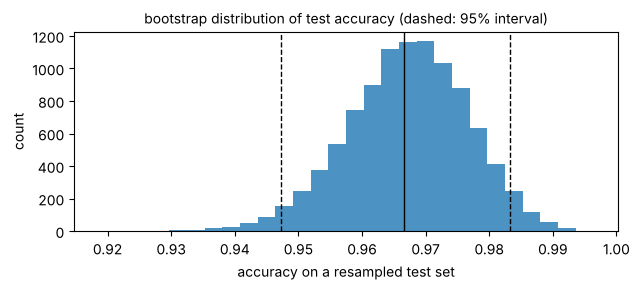

In [6]:
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

Xd, yd = load_digits(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.2, random_state=0, stratify=yd)
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xtr, ytr)
correct = (clf.predict(Xte) == yte).astype(float)               # 1 if the test image was classified correctly
n_te, acc = len(correct), correct.mean()
se = np.sqrt(acc * (1 - acc) / n_te)
print(f"test accuracy {acc:.4f} on {n_te} test images ({int(correct.sum())} correct); standard error {se:.4f}")
print(f"normal-approximation 95% interval: {acc - 1.96 * se:.4f} to {acc + 1.96 * se:.4f}")

rng = np.random.default_rng(5)
B = 10000
boot = correct[rng.integers(0, n_te, size=(B, n_te))].mean(axis=1)   # B resampled test sets, one accuracy each
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"bootstrap, {B} resamples: 95% percentile interval {lo:.4f} to {hi:.4f}; bootstrap standard error {boot.std(ddof=1):.4f}")

plt.figure(figsize=(6.5, 3))
plt.hist(boot, bins=np.arange(0.92, 1.0001, 1 / n_te) - 0.5 / n_te, color="C0", alpha=0.8)
for v, ls in [(lo, "--"), (hi, "--"), (acc, "-")]:
    plt.axvline(v, color="k", ls=ls, lw=1)
plt.xlabel("accuracy on a resampled test set"); plt.ylabel("count"); plt.title("bootstrap distribution of test accuracy (dashed: 95% interval)", fontsize=10)
plt.tight_layout(); plt.show()

### 7. What "95%" means: coverage
A 95% interval is a **procedure**: if the experiment is repeated many times, about 95% of the intervals it builds contain the true value. We cannot check that on real data, because the true accuracy is unknown, so we simulate a classifier whose true accuracy is exactly 0.9. Each experiment draws a test set of 100 answers, builds both intervals (the bootstrap with 1,000 resamples), and checks whether 0.9 is inside.

1000 simulated experiments, true accuracy 0.9, 100 test answers each:
normal-approximation intervals contained the true value 0.938 of the time
bootstrap percentile intervals contained the true value 0.956 of the time (in 32 experiments a bootstrap endpoint was exactly 0.90)
of the first 50 bootstrap intervals, 49 contain 0.9 and 1 miss it


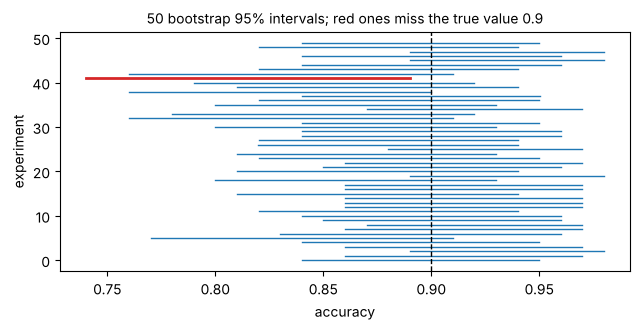

runtime so far 4 s


In [7]:
rng = np.random.default_rng(6)
p_true, n_small, reps, B_small = 0.9, 100, 1000, 1000
hits_normal, hits_boot, on_edge, ints = 0, 0, 0, []
for r in range(reps):
    c = (rng.random(n_small) < p_true).astype(float)              # one simulated test set: 1 = correct
    a = c.mean(); s = np.sqrt(a * (1 - a) / n_small)
    bl, bh = np.percentile(c[rng.integers(0, n_small, size=(B_small, n_small))].mean(axis=1), [2.5, 97.5])
    hits_normal += (a - 1.96 * s <= p_true <= a + 1.96 * s); hits_boot += (bl <= p_true <= bh)
    on_edge += (bl == p_true) or (bh == p_true)                     # an endpoint exactly at 0.90
    ints.append((bl, bh))
print(f"{reps} simulated experiments, true accuracy {p_true}, {n_small} test answers each:")
print(f"normal-approximation intervals contained the true value {hits_normal / reps:.3f} of the time")
print(f"bootstrap percentile intervals contained the true value {hits_boot / reps:.3f} of the time "
      f"(in {on_edge} experiments a bootstrap endpoint was exactly 0.90)")
ints = np.array(ints[:50]); miss = (ints[:, 0] > p_true) | (ints[:, 1] < p_true)
print(f"of the first 50 bootstrap intervals, {int((~miss).sum())} contain 0.9 and {int(miss.sum())} miss it")

plt.figure(figsize=(6.5, 3.4))
for i, (l, h) in enumerate(ints):
    plt.plot([l, h], [i, i], color="C3" if miss[i] else "C0", lw=2 if miss[i] else 1)
plt.axvline(p_true, color="k", ls="--", lw=1)
plt.xlabel("accuracy"); plt.ylabel("experiment"); plt.title("50 bootstrap 95% intervals; red ones miss the true value 0.9", fontsize=10)
plt.tight_layout(); plt.show()
print(f"runtime so far {time.time() - t_start:.0f} s")

### 8. The same on a full-size test set (NOT RUN here)
MNIST has 10,000 test images, about 28 times more than the 360 above, so its interval is about $\sqrt{28} \approx 5.3$ times narrower. Loading it needs a download.

In [ ]:
# NOT RUN: needs a download of MNIST from OpenML (about 50 MB) and a few minutes of CPU time
from sklearn.datasets import fetch_openml
Xm, ym = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True)
Xm = Xm / 255.0
clf_m = LogisticRegression(max_iter=200).fit(Xm[:60000], ym[:60000])
correct_m = (clf_m.predict(Xm[60000:]) == ym[60000:]).astype(float)
boot_m = correct_m[np.random.default_rng(0).integers(0, len(correct_m), size=(2000, len(correct_m)))].mean(axis=1)
print(f"MNIST test accuracy {correct_m.mean():.4f}, 95% bootstrap interval "
      f"{np.percentile(boot_m, 2.5):.4f} to {np.percentile(boot_m, 97.5):.4f}")

### 9. Exercises

In [8]:
# TODO: MAP for a Gaussian mean. The data come from N(mu, sigma^2) with sigma = 2 known, and the prior is
# mu ~ N(0, tau^2) with tau = 1. Set the derivative of the log posterior to zero by hand, write the MAP estimate
# as a formula in the data, and check it against a grid search over mu for the data 2, 4, 6.
def map_gaussian_mean(x, sigma=2.0, tau=1.0):
    return None          # replace with your formula

r = map_gaussian_mean(np.array([2.0, 4.0, 6.0]))
print("not done yet" if r is None else f"MAP estimate of mu: {r:.4f} (the MLE is the sample mean, 4.0)")

not done yet


In [9]:
# TODO: paired bootstrap. Train a second classifier on the same split, for example
# sklearn.neighbors.KNeighborsClassifier(n_neighbors=3). In each bootstrap round, resample the test INDICES once and
# use the same indices for both classifiers, so each round gives one difference in accuracy. Return
# (observed difference, 2.5th percentile, 97.5th percentile). Is the difference clearly different from zero?
def paired_bootstrap(B=10000):
    return None          # replace with your code

r = paired_bootstrap()
print("not done yet" if r is None else r)

not done yet


### What to notice
(Written from the run above; your numbers will match if you keep the seeds.)

1. **A prior rescues tiny samples.** After 3 heads in 3 flips the MLE was 1.000, which says tails is impossible; the Beta(2, 2) prior gave 0.800. For the data 2, 4, 6 the numerical MLE matched the formulas: $\hat\mu = 4$ and $\hat\sigma^2 = 2.6667$ (dividing by $n$; dividing by $n - 1$ gives 4.0).
2. **Losses are negative log-likelihoods.** Squared error and the Gaussian NLL chose the same slope (3.066), and the mean NLL computed by hand equalled scikit-learn's log loss (0.4987).
3. **A prior helps only when it is roughly right, and mainly with little data.** With true $p = 0.7$, the MAP estimate's MSE at $n = 3$ was 0.031 against 0.070 for the MLE. With $p = 0.95$, far from the prior's 0.5, MAP was worse: 0.038 against 0.015. By $n = 1000$ the two agreed (0.00021 for $p = 0.7$, 0.00005 for $p = 0.95$). The simulated MSEs matched the bias–variance formulas to within 2.5%.
4. **Unbiased is not the same as more accurate.** The $1/n$ variance estimate averaged 3.200 (true value 4) and the $1/(n-1)$ estimate 3.999, yet the biased one had the smaller MSE, 5.76 against 8.00, exactly as the formulas predict.
5. **Ridge is MAP, and here the best prior strength was $\sigma^2/\tau^2$.** The numerical MAP, the closed form and scikit-learn agreed (largest differences 2.9e-08 and 6.7e-16). The best $\lambda$ on the grid was 3.98 for both $n = 30$ and $n = 200$, next to $\sigma^2/\tau^2 = 4$. With 30 training points the prior cut the mean test MSE from 3.139 ($\lambda = 0.001$, almost no prior) to 2.091; with 200 points the gain was tiny (1.111 to 1.109). A prior far too strong ($\lambda = 1000$) hurt both (5.610 and 4.557). This works so neatly only because the true weights were drawn from the prior; on real data, tune $\lambda$ on validation data.
6. **A test accuracy carries an error bar of about ±2 points here.** The classifier got 348 of 360 test images right (0.9667), with standard error 0.0095. The normal interval was 0.9481 to 0.9852 and the bootstrap interval 0.9472 to 0.9833. Two classifiers one point apart on this test set cannot be told apart.
7. **"95%" describes the procedure, not one interval.** Over 1,000 simulated test sets with true accuracy 0.9, the normal intervals contained 0.9 in 0.938 of the experiments and the bootstrap intervals in 0.956 (the simulation's own standard error is about 0.007). Against expectation, the bootstrap came out above 95%. Part of the reason is discreteness: with 100 answers its endpoints sit on multiples of 0.01, and in 32 experiments an endpoint was exactly 0.90, which counts as a hit. Of the first 50 bootstrap intervals, 49 contained 0.9.